# 01 · Un torneo explicado: el run canónico

El **run canónico** es el torneo de referencia del proyecto, versionado en
`results/canonical/`: las **36 estrategias** del roster oficial, clasificatoria
(todos contra todos) y luego **6 ligas de 6** durante **20 temporadas**, con 2 ascensos y
2 descensos por liga, partidos de 100 rondas, **sin ruido** y semilla 42.

Para regenerarlo (sale idéntico byte a byte):

```
split-steal tournament --name canonical --out-dir results
split-steal plot results/canonical
```

> Ojo: es **un solo torneo** (una semilla). Sirve para ver cómo funciona todo; las
> conclusiones robustas, con 50 semillas por condición, están en `02_experimentos.ipynb`.

In [1]:
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import display

from split_steal import plots
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 2)
from split_steal.runner import load_run

result = load_run("../results/canonical")
print(f"{len(result.strategies)} estrategias · {len(result.matches)} partidos · "
      f"{result.matches[['cc', 'cd', 'dc', 'dd']].to_numpy().sum():,} rondas")

36 estrategias · 2430 partidos · 243,000 rondas


## 1. La clasificatoria: todas contra todas

En la temporada 0 cada estrategia juega contra las otras 35. Es la comparación más justa:
todas tienen los mismos rivales. Las líneas marcan lo que se gana por ronda si ambos
cooperan siempre (3) o si ambos se traicionan siempre (1).

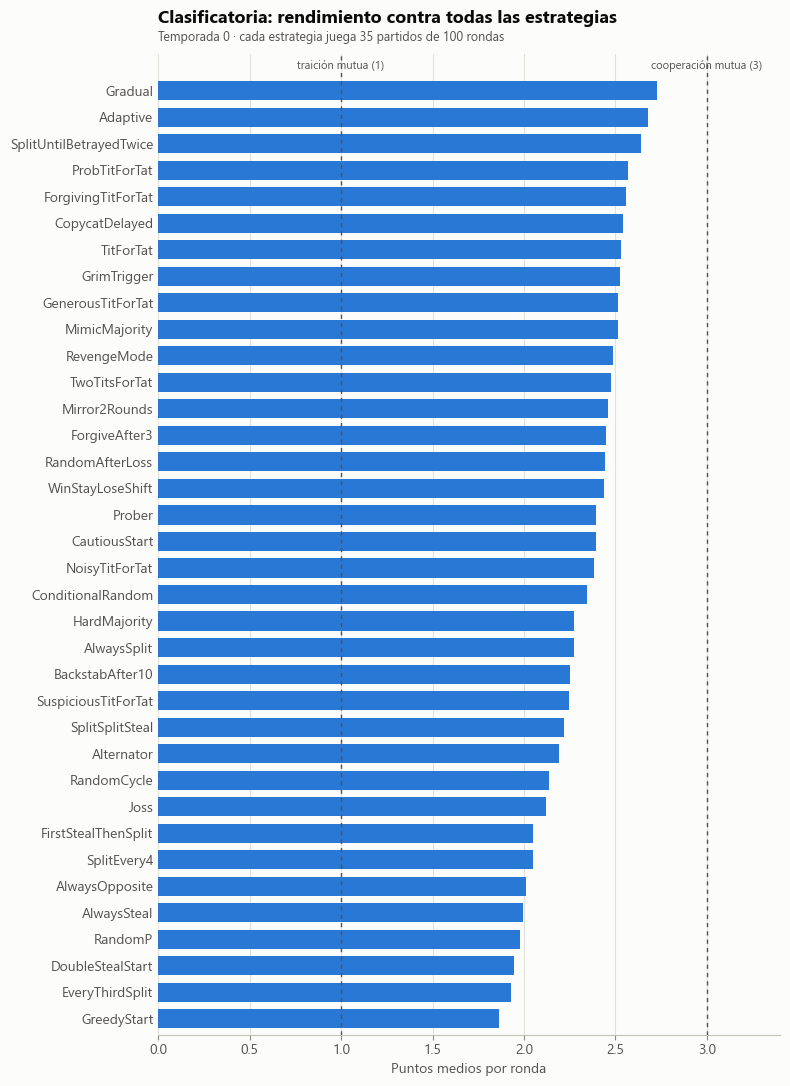

In [2]:
plots.plot_qualifying_points(result);

## 2. ¿Cooperar más hace ganar más?

Las mejores cooperan mucho, **pero no siempre**: castigan la traición. `AlwaysSplit`
coopera el 100 % de las rondas y queda en la mitad baja porque la explotan.

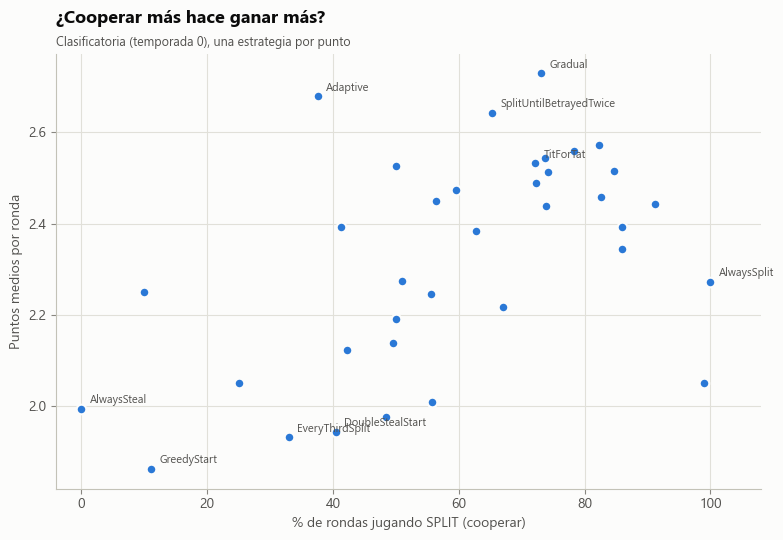

In [3]:
plots.plot_cooperation_vs_payoff(result);

## 3. ¿Quién gana a quién?

Cada celda es la diferencia de puntos por ronda entre la fila y la columna (todas las
temporadas). Azul: la fila gana; rojo: pierde. Las celdas vacías son parejas que nunca
se cruzaron (estaban en ligas distintas).

Fíjate en la **primera fila**: las que más ganan a sus rivales son traicioneras, pero
no son las que mejor quedan en el torneo. En un juego que no es de suma cero, lo que
cuenta es cuánto sumas, no a cuántos ganas.

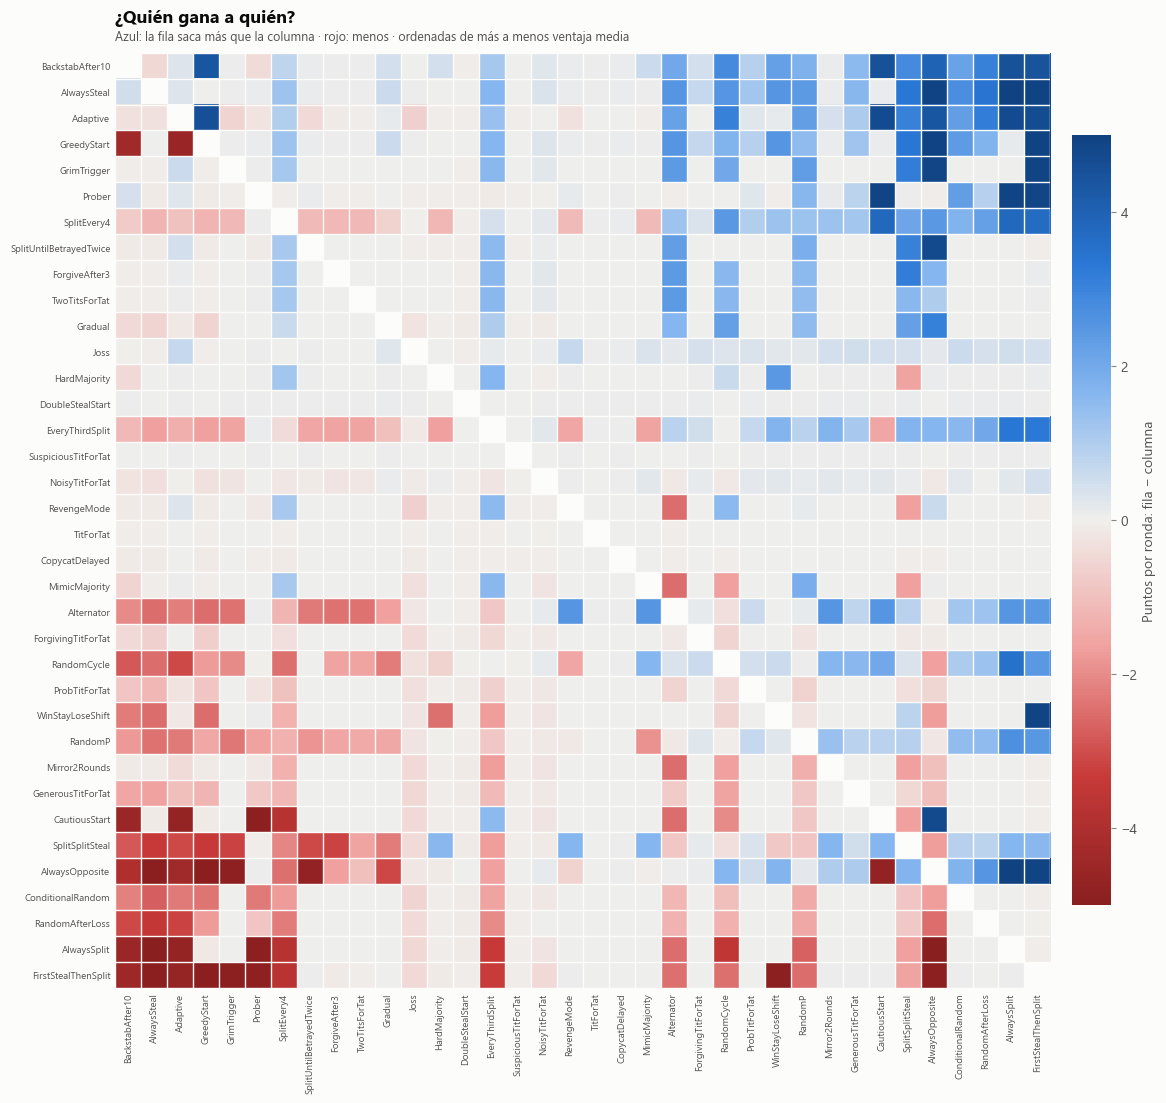

In [4]:
plots.plot_head_to_head(result.matches);

## 4. Cómo se comporta cada estrategia

Calculado a partir de los partidos (`strategy_stats.csv`), en la clasificatoria:

- `coop_rate`: % de rondas en que coopera.
- `betrayed`: rondas en que cooperó y le robaron.
- `retaliation_rate`: tras un robo del rival, % de veces que responde robando.
- `peace_rate`: tras una traición mutua, % de veces que vuelve a cooperar.

In [5]:
s = result.strategy_stats
q = s[s.season == 0].set_index("name")
q["points_per_round"] = q.points / q.rounds_played
cols = ["points_per_round", "coop_rate", "betrayed", "stole", "retaliation_rate", "peace_rate"]
q[cols].sort_values("points_per_round", ascending=False)

,points_per_round,coop_rate,betrayed,stole,retaliation_rate,peace_rate
name,,,,,,
Gradual,2.73,0.73,129,331,0.89,7.12e-02
Adaptive,2.68,0.38,144,920,0.89,6.48e-02
SplitUntilBetrayedTwice,2.64,0.65,29,317,0.98,0.00e+00
ProbTitForTat,2.57,0.82,374,216,0.81,2.03e-01
ForgivingTitForTat,2.56,0.78,336,246,0.90,1.05e-01
CopycatDelayed,2.54,0.74,320,300,0.64,2.44e-01
TitForTat,2.53,0.72,347,338,1.00,0.00e+00
GrimTrigger,2.53,0.50,18,474,1.00,0.00e+00
GenerousTitForTat,2.52,0.85,409,152,0.68,3.28e-01


## 5. Las ligas: quién sube y quién baja

Tras la clasificatoria, cada bloque de 6 forma una liga (Liga 1 = la mejor). Cada
temporada los 2 primeros suben y los 2 últimos bajan. Las cooperadoras se asientan arriba;
las traicioneras hacen de **"ascensor"**: suben explotando a las ingenuas de las ligas
bajas y bajan al chocar con las vengativas.

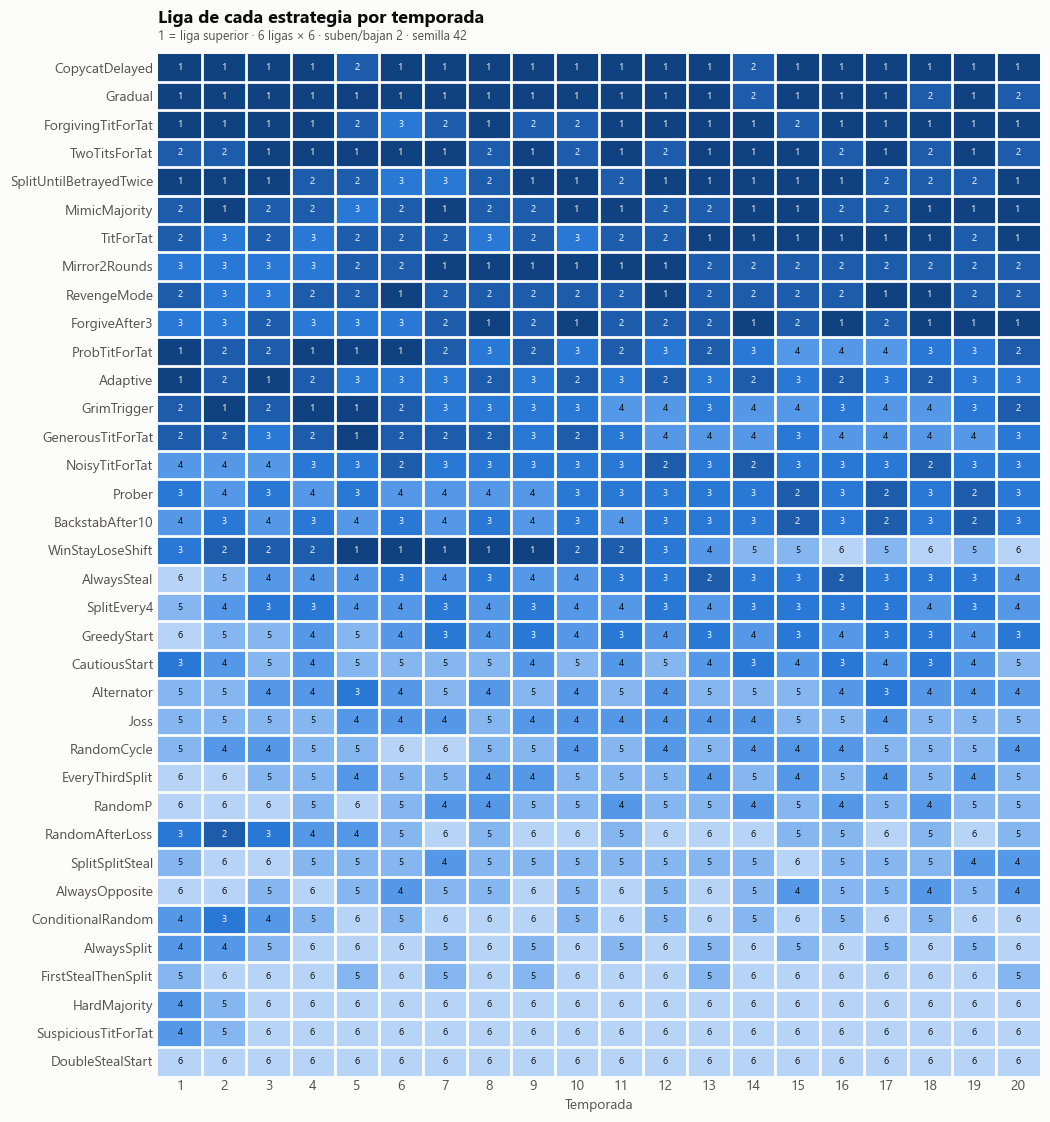

In [6]:
plots.plot_leagues_by_season(result);

In [7]:
st = result.standings
seasons = st[st.season > 0].sort_values(["name", "season"])
moves = seasons.groupby("name")["league"].apply(lambda x: int((x.diff().abs() > 0).sum()))
(seasons.groupby("name")["league"].agg(liga_media="mean", mejor="min", peor="max")
 .assign(cambios_de_liga=moves).sort_values("liga_media"))

,liga_media,mejor,peor,cambios_de_liga
name,,,,
CopycatDelayed,1.10,1,2,4
Gradual,1.15,1,2,5
ForgivingTitForTat,1.35,1,3,8
TwoTitsForTat,1.40,1,2,12
SplitUntilBetrayedTwice,1.55,1,3,8
MimicMajority,1.60,1,3,11
TitForTat,1.85,1,3,11
RevengeMode,1.90,1,3,8
Mirror2Rounds,1.90,1,3,3


## 6. ¿Qué decide los ascensos y descensos?

Si dos estrategias empatan a puntos se desempata por: enfrentamiento directo, diferencia
de puntos y, si todo sigue igual, un **sorteo** con la semilla. La columna `decided_by` de
`standings.csv` dice qué criterio separó a cada estrategia de la siguiente.

Miramos la frontera de descenso de cada liga (el último que se salva frente al primero que
baja). En la Liga 1 se juntan cooperadoras que empatan en todo: sin ruido, **casi todos sus
descensos los decide el sorteo**.

In [8]:
n, k = result.config.n_per_league, result.config.n_ascend_descend
frontier = seasons[(seasons.position == n - k) & (seasons.league < result.config.n_leagues)]
pd.crosstab(frontier.league, frontier.decided_by).rename_axis(index="liga", columns="decidido por")

decidido por,draw,points
liga,,
1,18,2
2,7,13
3,0,20
4,0,20
5,0,20


## 7. Clasificación final

La clasificación final ordena la última temporada por liga y posición (1 = campeón de la
Liga 1). Es la misma medida que se promedia entre semillas en los experimentos.

In [9]:
result.final_ranking.head(12)

,rank,name,league,position,points
0,1,CopycatDelayed,1,1,1500
1,2,ForgivingTitForTat,1,2,1500
2,3,MimicMajority,1,3,1500
3,4,SplitUntilBetrayedTwice,1,4,1500
4,5,ForgiveAfter3,1,5,1500
5,6,TitForTat,1,6,1500
6,7,ProbTitForTat,2,1,1500
7,8,TwoTitsForTat,2,2,1500
8,9,GrimTrigger,2,3,1500
9,10,Mirror2Rounds,2,4,1500
